In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
import seaborn as sns
import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [2]:
import sys, os

project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.append(project_root)

print(project_root)

c:\Users\fayem\OneDrive - Ecole Centrale Casablanca\Desktop\Datacamp\projets


In [3]:
from data.loading_data import data

In [4]:
print(data.head())

      price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  13300000  7420         4          2        3      yes        no       no   
1  12250000  8960         4          4        4      yes        no       no   
2  12250000  9960         3          2        2      yes        no      yes   
3  12215000  7500         4          2        2      yes        no      yes   
4  11410000  7420         4          1        2      yes       yes      yes   

  hotwaterheating airconditioning  
0              no             yes  
1              no             yes  
2              no              no  
3              no             yes  
4              no             yes  


In [5]:
data.describe()

,price,area,bedrooms,bathrooms,stories
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   price            545 non-null    int64 
 1   area             545 non-null    int64 
 2   bedrooms         545 non-null    int64 
 3   bathrooms        545 non-null    int64 
 4   stories          545 non-null    int64 
 5   mainroad         545 non-null    object
 6   guestroom        545 non-null    object
 7   basement         545 non-null    object
 8   hotwaterheating  545 non-null    object
 9   airconditioning  545 non-null    object
dtypes: int64(5), object(5)
memory usage: 42.7+ KB


In [7]:
from src.outliers import find_outliers

out = find_outliers(data)
out

{'price': 15.0,
 'area': 12.0,
 'bedrooms': 12.0,
 'bathrooms': 1.0,
 'stories': 41.0}

In [8]:
data.isna().sum() # number of missing values

price              0
area               0
bedrooms           0
bathrooms          0
stories            0
mainroad           0
guestroom          0
basement           0
hotwaterheating    0
airconditioning    0
dtype: int64

In [9]:
from src.outliers import find_outliers

out = find_outliers(data)

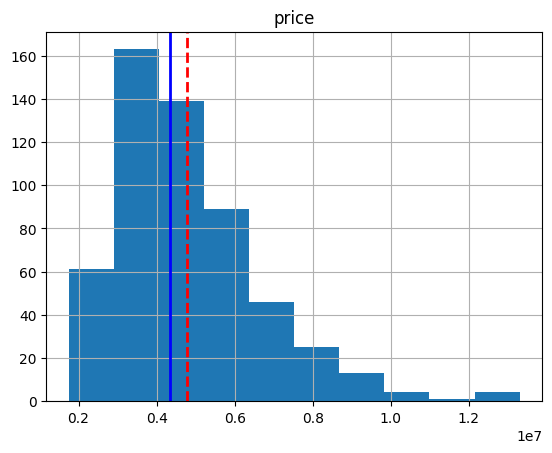

In [10]:
# histogram of target value
moyenne = data['price'].mean()
mediane = data['price'].median()

data["price"].hist(bins=10)

plt.axvline(moyenne, color='red', linestyle='--', linewidth=2, label=f'Moyenne={moyenne:.2f}')

plt.axvline(mediane, color='blue', linestyle='-', linewidth=2, label=f'Médiane={mediane:.2f}')

plt.title('price')

plt.show()

In [11]:
# the skewness

skw = data['price'].skew() # skewness without any transformation

# log transformation
data['price_log'] = np.log1p(data['price'])
log_skw = data['price_log'].skew()

# bocox tranformation
data['price_boxcox'], best_lambda = stats.boxcox(data['price'])
boxcox_skw = data['price_boxcox'].skew()

print('skewness without log = ', skw)
print('skewness with log = ', log_skw)

print("Lambda optimal trouvé :", best_lambda)
print("Skewness with box-cox :", boxcox_skw)

skewness without log =  1.2122388370279802
skewness with log =  0.14086281102108905
Lambda optimal trouvé : -0.13464661287601734
Skewness with box-cox : 0.0027739025440641964


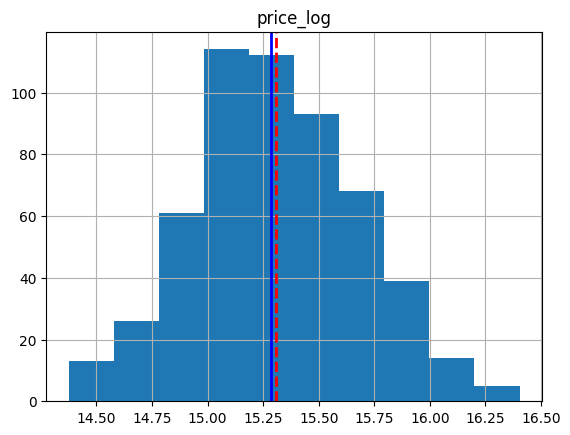

In [12]:
# histogram of target value
moyenne = data['price_log'].mean()
mediane = data['price_log'].median()

data["price_log"].hist(bins=10)

plt.axvline(moyenne, color='red', linestyle='--', linewidth=2, label=f'Moyenne={moyenne:.2f}')

plt.axvline(mediane, color='blue', linestyle='-', linewidth=2, label=f'Médiane={mediane:.2f}')

plt.title('price_log')

plt.show()

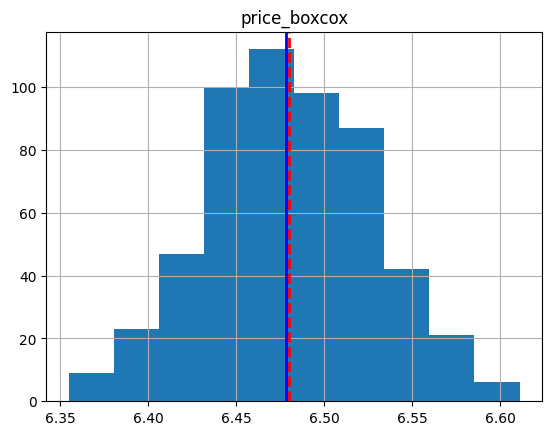

In [13]:
# histogram of target value
moyenne = data['price_boxcox'].mean()
mediane = data['price_boxcox'].median()

data["price_boxcox"].hist(bins=10)

plt.axvline(moyenne, color='red', linestyle='--', linewidth=2, label=f'Moyenne={moyenne:.2f}')

plt.axvline(mediane, color='blue', linestyle='-', linewidth=2, label=f'Médiane={mediane:.2f}')

plt.title('price_boxcox')

plt.show()

___the skewness without the log1p transformation is very high. So, we apply the a logarithmic and box-cox transformation to centrilize the target values.___  
___we can see that the cox-cox transformation gives the most centralize data___

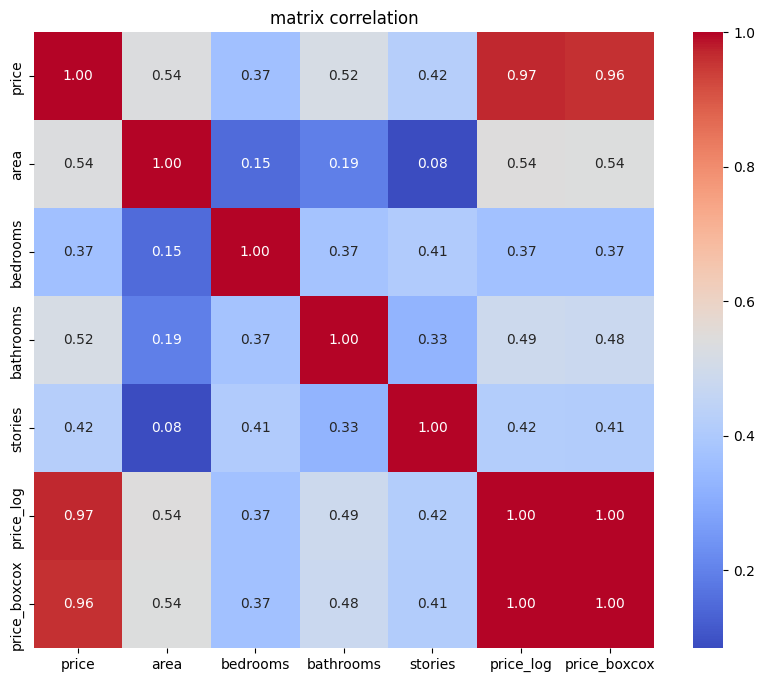

In [14]:
# correlation between variables

corr_matrix = data.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('matrix correlation')
plt.show()

In [15]:
cat_cols = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning']
data = pd.get_dummies(data, columns=cat_cols, drop_first=True)

In [16]:
data.head()

,price,area,bedrooms,bathrooms,stories,price_log,price_boxcox,mainroad_yes,guestroom_yes,basement_yes,hotwaterheating_yes,airconditioning_yes
0,13300000,7420,4,2,3,16.403275,6.611014,True,False,False,False,True
1,12250000,8960,4,4,4,16.321037,6.601930,True,False,False,False,True
2,12250000,9960,3,2,2,16.321037,6.601930,True,False,True,False,False
3,12215000,7500,4,2,2,16.318175,6.601612,True,False,True,False,True
4,11410000,7420,4,1,2,16.250001,6.594002,True,True,True,False,True


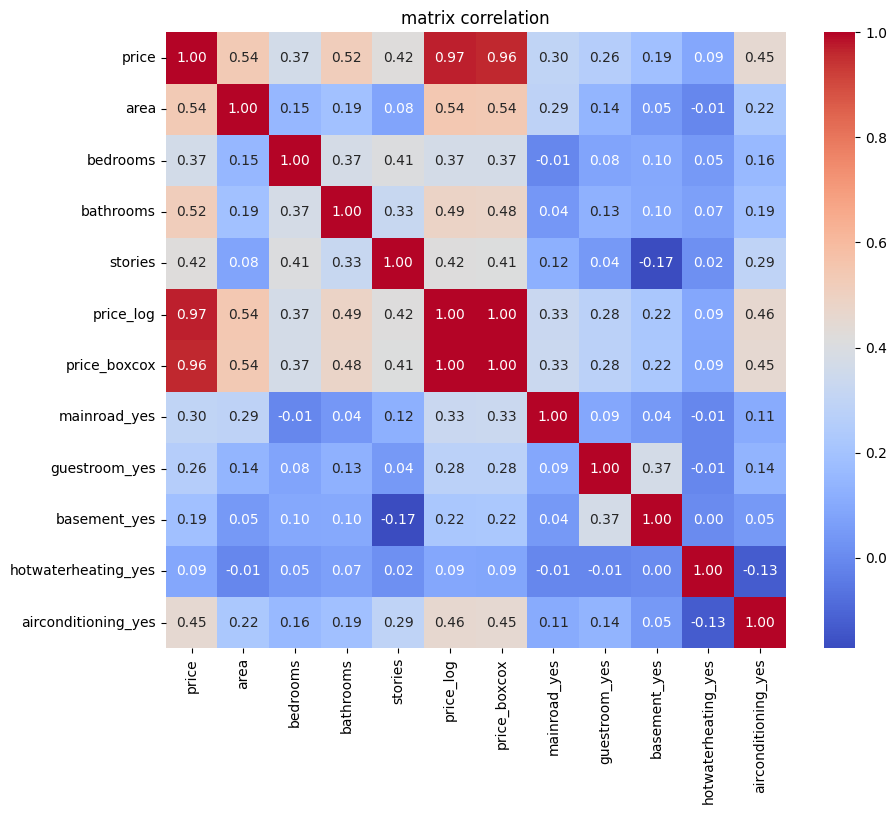

In [17]:
# correlation between variables

corr_matrix = data.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('matrix correlation')
plt.show()

In [18]:
"""Le VIF mesure à quel point une variable explicative est corrélée avec les autres variables
explicatives de votre modèle (pas avec la cible y, mais entre elles). C'est l'outil de référence
pour détecter la multicolinéarité — un problème où plusieurs variables X apportent
une information redondante entre elles."""

X = data.drop(columns=['price', 'price_log', 'price_boxcox'])  # vos features uniquement
bool_cols = X.select_dtypes(include='bool').columns
X[bool_cols] = X[bool_cols].astype(int)

vif_data = pd.DataFrame()
vif_data['feature'] = X.columns
vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

print(vif_data.sort_values('VIF', ascending=False))

               feature        VIF
1             bedrooms  15.155039
2            bathrooms   9.334010
3              stories   7.824157
0                 area   7.575941
4         mainroad_yes   6.657518
6         basement_yes   1.944371
8  airconditioning_yes   1.717668
5        guestroom_yes   1.460751
7  hotwaterheating_yes   1.077693
